# TRUSTSR Lab 05 — Recovery Execution and Independent Verification

**Phase:** Lab 05 — From policy simulation to an executable recovery prototype  
**Status:** Local synthetic prototype | Version 1.0.0

## Objective
Earlier labs evaluated quarantine policies on synthetic dependency graphs. This lab takes the next step: implement a small, executable recovery pipeline that:

1. records versioned state snapshots and dependency edges;
2. marks a synthetic source as compromised;
3. computes the forward contamination closure;
4. selects a prior trusted snapshot for each affected state;
5. restores only affected state while preserving unaffected state;
6. runs an independent post-recovery verifier;
7. compares selective recovery against full rollback using explicit metrics.

## Important evidence boundary
This is a local toy implementation over synthetic in-memory state. It is **not** a production agent framework, real memory-poisoning exploit, cryptographic trust system, or proof of TRUSTSR's real-world effectiveness. Results produced by this notebook are measured outputs of this simulator only. Do not describe them as production or deployment evidence.

## Recovery semantics
- Directed edge `u -> v` means state `v` may depend on or be influenced by state `u`.
- The compromised source and all nodes reachable from it are treated as affected.
- A trusted snapshot is a prior synthetic version captured before the injected compromise.
- Selective recovery restores affected nodes from trusted snapshots and leaves all other nodes unchanged.
- Full rollback restores every node from its trusted snapshot, including unaffected nodes.
- The verifier checks restored values against the trusted snapshot and checks that unaffected nodes were preserved by selective recovery. This verifier uses the simulator's trusted snapshot as an oracle; it is not an independent security oracle for real systems.

## 1. Configuration and imports

In [1]:
from collections import defaultdict, deque
from copy import deepcopy
from datetime import datetime, timezone
import json, platform, random, sys
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261015
N_TRIALS = 300
N_NODES = 40
EDGE_PROBABILITY = 0.07
N_COMPROMISED_SOURCES = 1

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence classification: local synthetic prototype")
print({"seed": SEED, "trials": N_TRIALS, "nodes": N_NODES,
       "edge_probability": EDGE_PROBABILITY})

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
Execution UTC: 2026-10-11T10:27:04.703265+00:00
Evidence classification: local synthetic prototype
{'seed': 20261015, 'trials': 300, 'nodes': 40, 'edge_probability': 0.07}


## 2. State graph and snapshot helpers

In [2]:
def make_dag(rng, n_nodes, edge_probability):
    nodes = [f"M{i:02d}" for i in range(n_nodes)]
    edges = [(nodes[i], nodes[j]) for i in range(n_nodes) for j in range(i + 1, n_nodes)
             if rng.random() < edge_probability]
    return nodes, edges

def forward_closure(nodes, edges, sources):
    adj = defaultdict(list)
    for u, v in edges:
        adj[u].append(v)
    seen, queue = set(sources), deque(sources)
    while queue:
        current = queue.popleft()
        for nxt in adj[current]:
            if nxt not in seen:
                seen.add(nxt)
                queue.append(nxt)
    return seen

def create_trusted_snapshot(nodes, rng):
    # Stable synthetic values; each node has a prior trusted version.
    return {node: {"version": 1, "value": f"trusted::{node}::{rng.randrange(100000, 999999)}"}
            for node in nodes}

def inject_compromise(state, source):
    corrupted = deepcopy(state)
    corrupted[source] = {
        "version": state[source]["version"] + 1,
        "value": f"COMPROMISED::{source}::synthetic-payload"
    }
    return corrupted

def restore_nodes(current_state, trusted_snapshot, restore_set):
    restored = deepcopy(current_state)
    for node in restore_set:
        restored[node] = deepcopy(trusted_snapshot[node])
    return restored

def independent_checks(recovered, trusted_snapshot, original_compromised_state,
                       affected, nodes, mode):
    # Independent function boundary, but the synthetic trusted snapshot is still
    # the ground-truth oracle. This validates implementation behavior only.
    bad_after = [n for n in nodes if recovered[n] != trusted_snapshot[n]]
    if mode == "selective":
        unaffected = set(nodes) - set(affected)
        changed_unaffected = [
            n for n in unaffected
            if recovered[n] != original_compromised_state[n]
        ]
    else:
        changed_unaffected = []
    return {
        "post_recovery_nodes_not_matching_trusted_snapshot": len(bad_after),
        "unaffected_nodes_changed_by_selective_recovery": len(changed_unaffected),
        "verification_pass": len(bad_after) == 0 and len(changed_unaffected) == 0
    }

print("Graph and snapshot helpers defined.")

Graph and snapshot helpers defined.


## 3. Run selective recovery vs full rollback

In [3]:
trial_rows, node_rows = [], []
for trial in range(N_TRIALS):
    rng = random.Random(SEED + trial)
    nodes, edges = make_dag(rng, N_NODES, EDGE_PROBABILITY)
    trusted = create_trusted_snapshot(nodes, rng)
    source = rng.choice(nodes[:max(2, N_NODES // 3)])
    compromised_state = inject_compromise(trusted, source)

    # Synthetic ground truth: source plus its forward dependency/influence closure.
    affected = forward_closure(nodes, edges, {source})
    # The injection itself alters the source; downstream states are treated as
    # semantically contaminated even if their literal stored values have not changed.
    selective_state = restore_nodes(compromised_state, trusted, affected)
    full_state = restore_nodes(compromised_state, trusted, set(nodes))

    selective_check = independent_checks(
        selective_state, trusted, compromised_state, affected, nodes, "selective"
    )
    full_check = independent_checks(
        full_state, trusted, compromised_state, affected, nodes, "full"
    )

    for mode, recovered, check, restore_set in [
        ("selective", selective_state, selective_check, affected),
        ("full_rollback", full_state, full_check, set(nodes))
    ]:
        restored_count = sum(recovered[n] == trusted[n] for n in nodes)
        residual_count = sum(recovered[n] != trusted[n] for n in nodes)
        clean_nodes = set(nodes) - affected
        clean_preserved = sum(recovered[n] == compromised_state[n] for n in clean_nodes)
        trial_rows.append({
            "trial": trial,
            "mode": mode,
            "node_count": len(nodes),
            "edge_count": len(edges),
            "compromised_source": source,
            "affected_node_count": len(affected),
            "restore_set_size": len(restore_set),
            "restored_nodes_matching_trusted": restored_count,
            "residual_nodes_not_matching_trusted": residual_count,
            "clean_nodes": len(clean_nodes),
            "clean_nodes_preserved": clean_preserved,
            "clean_preservation_rate": clean_preserved / len(clean_nodes) if clean_nodes else 0.0,
            "recovery_fraction": len(restore_set) / len(nodes),
            **check
        })
        for node in nodes:
            node_rows.append({
                "trial": trial, "mode": mode, "node": node,
                "is_source": node == source,
                "in_synthetic_affected_closure": node in affected,
                "was_restored": node in restore_set,
                "matches_trusted_snapshot": recovered[node] == trusted[node],
                "value_after_recovery": recovered[node]["value"]
            })

trial_df = pd.DataFrame(trial_rows)
node_df = pd.DataFrame(node_rows)
assert len(trial_df) == N_TRIALS * 2
assert len(node_df) == N_TRIALS * 2 * N_NODES
assert trial_df["verification_pass"].all()
assert (trial_df["residual_nodes_not_matching_trusted"] == 0).all()
assert trial_df["recovery_fraction"].between(0, 1).all()
assert trial_df["clean_preservation_rate"].between(0, 1).all()
print("Trial-mode evaluations:", len(trial_df))
print("Node-mode records:", len(node_df))
print("All recovery and verification assertions passed.")
display(trial_df.head())

Trial-mode evaluations: 600
Node-mode records: 24000
All recovery and verification assertions passed.


   trial           mode  node_count  edge_count compromised_source  affected_node_count  restore_set_size  restored_nodes_matching_trusted  residual_nodes_not_matching_trusted  clean_nodes  \
0      0      selective          40          67                M10                   10                10                               40                                    0           30   
1      0  full_rollback          40          67                M10                   10                40                               40                                    0           30   
2      1      selective          40          64                M02                   15                15                               40                                    0           25   
3      1  full_rollback          40          64                M02                   15                40                               40                                    0           25   
4      2      selective          40     

## 4. Aggregate metrics and compare policies

In [4]:
METRICS = [
    "affected_node_count", "restore_set_size", "restored_nodes_matching_trusted",
    "residual_nodes_not_matching_trusted", "clean_preservation_rate",
    "recovery_fraction", "unaffected_nodes_changed_by_selective_recovery"
]
summary_df = trial_df.groupby("mode")[METRICS].agg(["mean", "std"]).reset_index()
summary_df.columns = [
    "_".join(str(x) for x in col if str(x) != "").rstrip("_")
    if isinstance(col, tuple) else col for col in summary_df.columns
]
display(summary_df)

means = trial_df.groupby("mode")[
    ["restore_set_size", "residual_nodes_not_matching_trusted",
     "clean_preservation_rate", "recovery_fraction"]
].mean().reset_index()
display(means)

# Paired trial comparison: selective recovery should restore no more nodes than full rollback.
paired = trial_df.pivot(index="trial", columns="mode", values="restore_set_size")
assert (paired["selective"] <= paired["full_rollback"]).all()
# Full rollback restores every node in this synthetic model.
assert (trial_df[trial_df["mode"] == "full_rollback"]["restore_set_size"] == N_NODES).all()
print("Selective-vs-full-rollback invariants passed.")

            mode  affected_node_count_mean  affected_node_count_std  restore_set_size_mean  restore_set_size_std  restored_nodes_matching_trusted_mean  restored_nodes_matching_trusted_std  \
0  full_rollback                  7.686667                  5.11557              40.000000               0.00000                                  40.0                                  0.0   
1      selective                  7.686667                  5.11557               7.686667               5.11557                                  40.0                                  0.0   

   residual_nodes_not_matching_trusted_mean  residual_nodes_not_matching_trusted_std  clean_preservation_rate_mean  clean_preservation_rate_std  recovery_fraction_mean  recovery_fraction_std  \
0                                       0.0                                      0.0                           1.0                          0.0                1.000000               0.000000   
1                                     

            mode  restore_set_size  residual_nodes_not_matching_trusted  clean_preservation_rate  recovery_fraction
0  full_rollback         40.000000                                  0.0                      1.0           1.000000
1      selective          7.686667                                  0.0                      1.0           0.192167

Selective-vs-full-rollback invariants passed.


## 5. Plot recovery cost and clean-work preservation

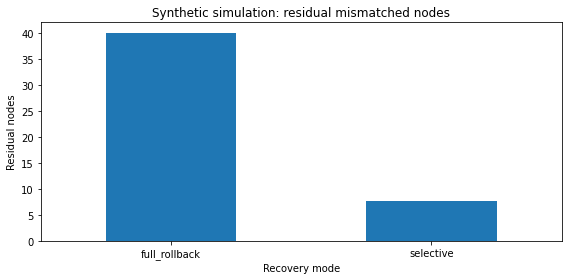

In [5]:
for metric, title, ylabel in [
    ("restore_set_size", "Synthetic simulation: number of nodes restored", "Nodes restored"),
    ("recovery_fraction", "Synthetic simulation: fraction of state restored", "Fraction restored"),
    ("clean_preservation_rate", "Synthetic simulation: unaffected clean-state preservation", "Preservation rate"),
    ("residual_nodes_not_matching_trusted", "Synthetic simulation: residual mismatched nodes", "Residual nodes")
]:
    ax = trial_df.groupby("mode")[metric].mean().plot(kind="bar", figsize=(8, 4))
    ax.set_title(title)
    ax.set_xlabel("Recovery mode")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

## 6. Failure injection: incomplete dependency graph

   missing_edge_rate  missed_affected_nodes  residual_affected_nodes  false_negative_rate_on_affected_closure  planned_restore_nodes
0               0.00               0.000000                      0.0                                 0.000000               7.383333
1               0.10               1.143333                      0.0                                 0.121901               6.246667
2               0.25               2.850000                      0.0                                 0.304813               4.966667
3               0.40               3.323333                      0.0                                 0.376639               3.953333

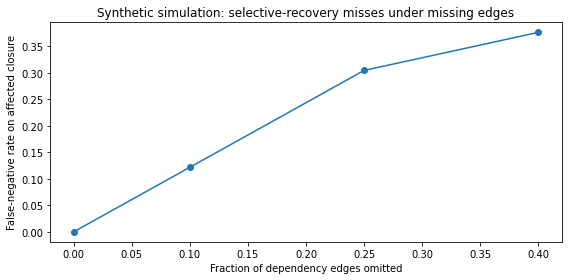

In [6]:
# A controlled failure test: remove a fraction of graph edges from the recovery planner.
# Ground truth still uses the complete graph. This measures how an incomplete graph
# can cause selective recovery to miss semantically affected nodes.
failure_rows = []
for missing_rate in [0.0, 0.10, 0.25, 0.40]:
    for trial in range(N_TRIALS):
        rng = random.Random(SEED + 500000 + int(missing_rate * 1000) * N_TRIALS + trial)
        nodes, true_edges = make_dag(rng, N_NODES, EDGE_PROBABILITY)
        trusted = create_trusted_snapshot(nodes, rng)
        source = rng.choice(nodes[:max(2, N_NODES // 3)])
        compromised = inject_compromise(trusted, source)
        true_affected = forward_closure(nodes, true_edges, {source})

        observed_edges = [e for e in true_edges if rng.random() >= missing_rate]
        planned_affected = forward_closure(nodes, observed_edges, {source})
        recovered = restore_nodes(compromised, trusted, planned_affected)

        missed_affected = true_affected - planned_affected
        residual_affected = [n for n in true_affected if recovered[n] != trusted[n]]
        failure_rows.append({
            "missing_edge_rate": missing_rate,
            "trial": trial,
            "true_affected_nodes": len(true_affected),
            "planned_restore_nodes": len(planned_affected),
            "missed_affected_nodes": len(missed_affected),
            "residual_affected_nodes": len(residual_affected),
            "false_negative_rate_on_affected_closure":
                len(missed_affected) / len(true_affected) if true_affected else 0.0
        })

failure_df = pd.DataFrame(failure_rows)
assert failure_df["false_negative_rate_on_affected_closure"].between(0, 1).all()
assert (failure_df[failure_df["missing_edge_rate"] == 0.0]["missed_affected_nodes"] == 0).all()
failure_summary = failure_df.groupby("missing_edge_rate")[
    ["missed_affected_nodes", "residual_affected_nodes",
     "false_negative_rate_on_affected_closure", "planned_restore_nodes"]
].mean().reset_index()
display(failure_summary)

ax = failure_summary.plot(
    x="missing_edge_rate",
    y="false_negative_rate_on_affected_closure",
    marker="o", figsize=(8, 4), legend=False
)
ax.set_title("Synthetic simulation: selective-recovery misses under missing edges")
ax.set_xlabel("Fraction of dependency edges omitted")
ax.set_ylabel("False-negative rate on affected closure")
plt.tight_layout()
plt.show()

## 7. Export all results

In [7]:
trial_df.to_csv("trustsr_lab05_recovery_trial_results.csv", index=False)
node_df.to_csv("trustsr_lab05_recovery_node_results.csv", index=False)
summary_df.to_csv("trustsr_lab05_recovery_summary_mean_std.csv", index=False)
failure_df.to_csv("trustsr_lab05_missing_graph_failure_trials.csv", index=False)
failure_summary.to_csv("trustsr_lab05_missing_graph_failure_summary.csv", index=False)

exports = [
    "trustsr_lab05_recovery_trial_results.csv",
    "trustsr_lab05_recovery_node_results.csv",
    "trustsr_lab05_recovery_summary_mean_std.csv",
    "trustsr_lab05_missing_graph_failure_trials.csv",
    "trustsr_lab05_missing_graph_failure_summary.csv"
]
print("CSV exports created:")
for name in exports:
    print("-", name)
print("Evidence classification: local synthetic prototype only.")

CSV exports created:
- trustsr_lab05_recovery_trial_results.csv
- trustsr_lab05_recovery_node_results.csv
- trustsr_lab05_recovery_summary_mean_std.csv
- trustsr_lab05_missing_graph_failure_trials.csv
- trustsr_lab05_missing_graph_failure_summary.csv
Evidence classification: local synthetic prototype only.


## 8. Interpretation and research limitations

### What this lab can support
- The code implements a concrete, runnable selective-recovery path over synthetic state and dependency data.
- The assertions test internal consistency of this implementation under its stated assumptions.
- The missing-edge experiment demonstrates how incomplete dependency knowledge can leave nodes in the synthetic affected closure unrestored.
- CSV outputs allow review of individual trials rather than relying only on plots.

### What this lab cannot support
- It does not establish that TRUSTSR works on a real agent framework.
- It does not establish that the graph captures all real causal dependencies.
- It does not provide cryptographic snapshot integrity, durable event logs, authorization, crash consistency, concurrent-write safety, or rollback of external side effects.
- The “independent verifier” is a separate function but still checks against the simulator's trusted snapshot. It is not independent ground truth in a deployed system.
- Zero residual mismatches in the primary experiment follow from restoring the complete synthetic affected closure. They are not a general guarantee.

### Publication wording
“We implemented a minimal synthetic recovery prototype that compares selective restoration of the graph-reachable affected closure with full rollback. We also injected missing dependency edges to measure residual affected state. All results are simulator-derived and do not establish production effectiveness or formal security guarantees.”

### Lab 05 completion checklist
1. Run all cells in a fresh Google Colab runtime.
2. Verify all assertions pass.
3. Inspect the missing-edge failure summary and all plots.
4. Download the five CSV exports.
5. Upload the executed notebook or PDF for review before adding runtime-specific integration.